# 02_5. Importance in the model: SHAP, permutation, Boruta / Важность в модели: SHAP, permutation, Boruta

**EN.** Step 8 of the methodology. Steps 2–7 looked at each feature alone or in pairs. Here we ask how much a feature matters **inside a model** that sees all features together (CatBoost — the model M1 of stage 3), where a feature can be useful only through interactions or can be made unnecessary by others.

- **SHAP** (SHapley Additive exPlanations) splits each prediction (in logit units) into contributions of the features. Mean |SHAP| over many loans = how much the model relies on the feature on average.
- **Permutation importance**: shuffle one feature on *validation* and measure how much the AUC drops. Unlike SHAP it is measured out of time, on data the model has not seen; a drop ≤ 0 means the model does not gain from the feature on new data.
- **Boruta**: add a shuffled copy ("shadow") of every feature, refit, and count how often the real feature beats the best shadow; after 20 rounds a binomial test labels it *confirmed*, *tentative* or *rejected* (no better than noise).

**Rule fixed in advance** (`configs/features.yaml`): a feature is dropped only if Boruta *rejects* it **and** its permutation importance is ≤ 0. Otherwise it stays.

Population: Y1 observations of loans that are **current at t** (DPD = 0) and have never been in default before t (only the first default counts), so the model has to warn before any delinquency is visible. The 10 delinquency-history features (`dpd` and its history) are not candidates, which leaves 59; 21 of them remain after step 5. CatBoost here is untuned (300 trees, depth 6, learning rate 0.1), trained on the full train with r = 0.2 and weights 1/r (2,294,292 rows, 14,062 events on 7,068 loans) — enough to rank features; tuning is stage 3. Validation without hurricane rows. Results are cached in `data/interim/stage2/`, so re-running the notebook is fast; the first run is slow (Boruta alone took 23 minutes).

**RU.** Шаг 8 методологии. Шаги 2–7 смотрели на признак по одному или парами. Здесь вопрос: насколько признак важен **внутри модели**, которая видит все признаки вместе (CatBoost — модель M1 этапа 3). В модели признак может быть полезен только через взаимодействия или, наоборот, оказаться ненужным из-за других.

- **SHAP** раскладывает каждый прогноз (в логитах) на вклады признаков. Средний |SHAP| по многим кредитам — насколько модель в среднем опирается на признак.
- **Permutation importance**: перемешиваем один признак на *validation* и смотрим, насколько падает AUC. В отличие от SHAP это измерение на другом периоде, на данных, которых модель не видела; падение ≤ 0 значит, что на новых данных признак модели не помогает.
- **Boruta**: к каждому признаку добавляется перемешанная копия («тень»), модель переобучается, и считается, как часто настоящий признак важнее лучшей тени; после 20 раундов биномиальный тест присваивает статус *confirmed* (подтверждён), *tentative* (не определён) или *rejected* (не лучше шума).

**Правило зафиксировано заранее** (`configs/features.yaml`): признак удаляется, только если Boruta его *отвергает* **и** permutation importance ≤ 0. Иначе он остаётся.

Популяция: наблюдения Y1 по кредитам **без просрочки на t** (DPD = 0), ни разу не бывшим в дефолте до t (учитывается только первый дефолт), то есть модель должна предупреждать раньше, чем появится любая просрочка. 10 признаков истории просрочек (`dpd` и его история) не входят в кандидаты, остаётся 59; после шага 5 из них остался 21. CatBoost здесь без подбора (300 деревьев, глубина 6, шаг 0,1), обучен на полном train с r = 0,2 и весами 1/r (2 294 292 строки, 14 062 события у 7 068 кредитов) — этого достаточно, чтобы упорядочить признаки; подбор — на этапе 3. Validation без наблюдений с ураганами. Результаты кэшируются в `data/interim/stage2/`, поэтому повторный запуск быстрый; первый долгий (одна Boruta считалась 23 минуты).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

import time
from xai_ews.config import feature_config
from xai_ews.data.features import COLUMNS, candidate_features, categorical_features
from xai_ews.features.data import TASKS, CategoryEncoder, load_train, subsample, to_model_frame
from xai_ews.features.importance import (boruta, fit_predict_validation, permutation_importance,
                                         shap_importance)
from xai_ews.features.univariate import weighted_auc
from xai_ews.paths import FEATURE_SELECTION_DIR, STAGE2_INTERIM_DIR

CFG = feature_config()
RULES = CFG["rules"]["importance"]
SEED = CFG["data"]["seed"]
red = pd.read_csv(FEATURE_SELECTION_DIR / "redundancy.csv")
CAND = red.loc[red["pass_redundancy"], "feature"].tolist()
ALL = candidate_features()
CATS = categorical_features()
print(len(CAND), "candidates after redundancy;", RULES)

21 candidates after redundancy; {'train_rows': 400000, 'validation_rows': 500000, 'catboost': {'iterations': 300, 'depth': 6, 'learning_rate': 0.1}, 'boruta_iterations': 20, 'boruta_alpha': 0.05, 'permutation_repeats': 3, 'drop_if': 'boruta_rejected_both_and_permutation_le_zero_both'}


### 1. CatBoost on the candidates and on all 59 / CatBoost на кандидатах и на всех 59

**EN.** Two models: on the 21 candidates left after step 5, and on all 59 features (reference). The validation AUC of the two shows how much steps 2–5 cost. Predictions on validation are stored for the ablation notebook.

**RU.** Две модели: на 21 кандидате после шага 5 и на всех 59 признаках (эталон). AUC на validation двух моделей показывает, чего стоили шаги 2–5. Прогнозы на validation сохраняются для ноутбука абляции.

In [2]:
models, preds, aucs = {}, {}, []
for task in TASKS:
    for name, feats in [("candidates", CAND), ("all", ALL)]:
        t0 = time.time()
        p, m, enc = fit_predict_validation(task, feats, RULES["catboost"], f"m_{name}", seed=SEED)
        models[(task, name)], preds[(task, name)] = (m, enc, feats), p
        main = p.filter(~pl.col("val_hurricane_2017"))
        aucs.append({"task": task, "model": name, "features": len(feats),
                     "auc_val": weighted_auc(main[task].to_numpy(), main["logit"].to_numpy()),
                     "auc_val_with_hurricanes": weighted_auc(p[task].to_numpy(), p["logit"].to_numpy()),
                     "seconds": round(time.time() - t0)})
        gc.collect()
pd.DataFrame(aucs)

,task,model,features,auc_val,auc_val_with_hurricanes,seconds
0,y1,candidates,21,0.8510,0.8195,342
1,y1,all,59,0.8509,0.8220,444


**EN. How to read.** On validation without the hurricane rows the 21 candidates give AUC **0.851**, the same as all 59 features (0.851; the difference is 0.0001). Removing weak, unstable and duplicate features costs nothing. With the hurricane rows the AUCs are lower (0.820 and 0.822), and the two sets are again about equal. The level is lower than in the earlier version of this stage (about 0.93), and the reason is the task itself: the population now contains only loans that are current at t and have never been in default, and the delinquency-history features are gone, so the model no longer sees a delinquency that has already started or a past default. That was the easiest signal; now the model has to find future defaults among loans that are still paying on time. `seconds` = training time; 1 s means the model was taken from the cache. The formal comparison with confidence intervals is in 02_6.

**RU. Как читать.** На validation без наблюдений урагана 21 кандидат даёт AUC **0,851** — столько же, сколько все 59 признаков (0,851; разница 0,0001). Удаление слабых, нестабильных и дублирующих признаков ничего не стоит. С наблюдениями урагана AUC ниже (0,820 и 0,822), и наборы снова почти равны. Уровень ниже, чем в прежней версии этого этапа (около 0,93), и причина в самой задаче: теперь в популяции только кредиты без просрочки на t, ни разу не бывшие в дефолте, а признаков истории просрочек нет, поэтому модель больше не видит ни уже начавшуюся просрочку, ни прошлый дефолт. Это был самый лёгкий сигнал; теперь модель должна находить будущие дефолты среди кредитов, которые пока платят вовремя. `seconds` — время обучения; 1 с означает, что модель взята из кэша. Формальное сравнение с доверительными интервалами — в 02_6.

### 2. SHAP / SHAP

**EN.** Mean |SHAP| on 50,000 validation rows (logit scale) and its share of the total. For the all-59 model we also look at the features that steps 2–7 removed: if one of them had a large share, it would work through interactions and deserve a second look.

**RU.** Средний |SHAP| на 50 тыс. строк validation (шкала логитов) и его доля в сумме. Для модели на всех 59 смотрим также на признаки, удалённые шагами 2–7: если бы у какого-то из них была большая доля, он работал бы через взаимодействия и заслуживал бы второго взгляда.

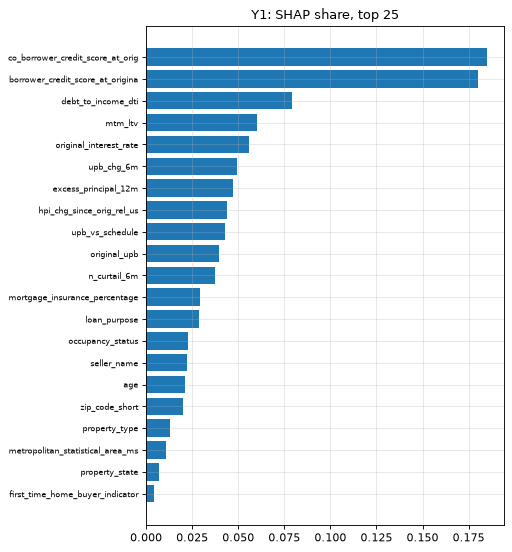

In [3]:
from xai_ews.features.data import load_validation
shap_tabs = {}
for task in TASKS:
    va = load_validation(task, ALL).sample(n=50_000, seed=SEED)
    for name in ["candidates", "all"]:
        m, enc, feats = models[(task, name)]
        shap_tabs[(task, name)] = shap_importance(m, to_model_frame(va, feats, enc), [c for c in CATS if c in feats])
    del va; gc.collect()

fig, axes = plt.subplots(1, len(TASKS), figsize=(5.5 * len(TASKS) + 1, 7), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    s = shap_tabs[(task, "candidates")].head(25).iloc[::-1]
    ax.barh([f[:32] for f in s["feature"]], s["shap_share"])
    ax.set_title(f"{task.upper()}: SHAP share, top 25"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

In [4]:
removed = [f for f in ALL if f not in CAND]
ref = pd.concat([shap_tabs[(t, "all")].assign(task=t) for t in TASKS])
ref = ref[ref["feature"].isin(removed)].pivot(index="feature", columns="task", values="shap_share")
ref["why_removed"] = ref.index.map(lambda f: red.set_index("feature")["redundancy_reason"].get(f) or "steps 2-7")
ref.sort_values("y1", ascending=False).head(15)

task,y1,why_removed
feature,,
original_combined_loan_to_value_ratio_cltv,0.0330,Y1: |rho| = 0.87 with mtm_ltv
current_interest_rate,0.0291,Y1: |rho| = 1.00 with original_interest_rate
number_of_borrowers,0.0238,Y1: |rho| = 0.77 with co_borrower_credit_score_at_origin...
n_curtail_12m,0.0201,Y1: |rho| = 0.90 with n_curtail_6m
original_loan_term,0.0166,Y1: |rho| = 0.70 with upb_chg_6m
upb_to_orig,0.0141,Y1: |rho| = 0.78 with upb_chg_6m
hpi_chg_12m_rel_us,0.0135,Y1: |rho| = 0.76 with hpi_chg_since_orig_rel_us
remaining_months_to_maturity,0.0126,Y1: |rho| = 0.80 with upb_chg_6m
sato,0.0121,Y1: |rho| = 0.85 with original_interest_rate


**EN. How to read and conclusion.** The model leans most on the two credit scores (co-borrower 18.5 %, borrower 18.0 % of total |SHAP|), then DTI (7.9 %), then mark-to-market LTV (6.0 %) and the rate (5.6 %), then the dynamic payment features: the 6-month balance change (5.0 %), excess principal paid over 12 months `excess_principal_12m` (4.7 %), the balance against the schedule `upb_vs_schedule` (4.3 %) and partial prepayments `n_curtail_6m` (3.8 %), and the local house-price change (4.4 %). Loan age `age` has 2.1 %. The 14 static features take about 70 % of total |SHAP|, the 7 dynamic ones about 30 %. Among the features removed earlier, the all-59 model gives the largest shares to **twins of kept features**: CLTV (3.3 %; twin of the current LTV), the current rate (2.9 %; twin of the original rate), number of borrowers (2.4 %; twin of the co-borrower score), the 12-month version of partial prepayments (2.0 %) and the original term (1.7 %; twin of the 6-month balance change). With twins present, the model simply splits the importance between them. Since the 21-feature model is as good as the 59-feature model, none of the removed features carries a signal that the kept ones lack.

**RU. Как читать и вывод.** Модель больше всего опирается на два кредитных рейтинга (созаёмщика — 18,5 %, заёмщика — 18,0 % суммарного |SHAP|), затем на DTI (7,9 %), затем на текущий LTV (6,0 %) и ставку (5,6 %), затем на динамические признаки платежей: изменение долга за 6 мес. (5,0 %), сверхплановое погашение за 12 мес. `excess_principal_12m` (4,7 %), остаток долга относительно графика `upb_vs_schedule` (4,3 %) и частичные досрочные погашения `n_curtail_6m` (3,8 %), а также на местную динамику цен (4,4 %). У возраста кредита `age` — 2,1 %. На 14 статических признаков приходится около 70 % суммарного |SHAP|, на 7 динамических — около 30 %. Среди удалённых ранее признаков модель на 59 признаках даёт наибольшие доли **двойникам оставленных**: CLTV (3,3 %; двойник текущего LTV), текущая ставка (2,9 %; двойник ставки при выдаче), число заёмщиков (2,4 %; двойник рейтинга созаёмщика), 12-месячная версия частичных погашений (2,0 %) и исходный срок (1,7 %; двойник изменения долга за 6 мес.). Когда двойники есть в модели, она просто делит важность между ними. Модель на 21 признаке не хуже модели на 59, значит, ни один удалённый признак не несёт сигнала, которого нет у оставленных.

### 3. Permutation importance on validation / Permutation importance на validation

**EN.** AUC drop when one candidate is shuffled, 3 repeats, on 500,000 validation rows (all events kept). Mean drop and its standard deviation across repeats.

**RU.** Падение AUC при перемешивании одного кандидата, 3 повтора, на 500 тыс. строк validation (все события сохранены). Среднее падение и его стандартное отклонение по повторам.

In [5]:
perm = {}
for task in TASKS:
    f_cache = STAGE2_INTERIM_DIR / f"permutation_{task}.csv"
    m, enc, feats = models[(task, "candidates")]
    if f_cache.exists() and set(pd.read_csv(f_cache)["feature"]) == set(feats):
        perm[task] = pd.read_csv(f_cache)
        continue
    va = subsample(load_validation(task, feats), task, RULES["validation_rows"], SEED)
    X = to_model_frame(va, feats, enc)
    perm[task] = permutation_importance(m, X, va[task].to_numpy(), [c for c in CATS if c in feats],
                                        repeats=RULES["permutation_repeats"], seed=SEED,
                                        w=va["sample_weight"].to_numpy())
    perm[task].to_csv(f_cache, index=False)
    del va, X; gc.collect()
pd.concat([perm[t].head(12).reset_index(drop=True).add_suffix(f"_{t}") for t in TASKS], axis=1)

,feature_y1,perm_auc_drop_y1,perm_auc_drop_sd_y1
0,borrower_credit_score_at_origination,0.0971,0.0017
1,co_borrower_credit_score_at_origination,0.0375,0.0026
2,upb_vs_schedule,0.0115,0.0002
3,excess_principal_12m,0.0068,0.0006
4,debt_to_income_dti,0.0066,0.0002
5,mtm_ltv,0.0057,0.0006
6,original_interest_rate,0.0055,0.0007
7,n_curtail_6m,0.0051,0.0002
8,upb_chg_6m,0.0035,0.0004
9,original_upb,0.0028,0.0005


### 4. Boruta / Boruta

**EN.** 400,000 train rows (all events, weights rescaled), 20 rounds of CatBoost with shadows of every candidate. With 20 rounds and the 5 % level with Bonferroni correction over the 21 candidates, *confirmed* needs ≥ 17 hits and *rejected* ≤ 3.

**RU.** 400 тыс. строк train (все события, веса пересчитаны), 20 раундов CatBoost с тенями всех кандидатов. При 20 раундах и уровне 5 % с поправкой Бонферрони на 21 кандидата статус *confirmed* требует ≥ 17 побед, *rejected* — ≤ 3.

In [6]:
bor = {}
for task in TASKS:
    f_cache = STAGE2_INTERIM_DIR / f"boruta_{task}.csv"
    if f_cache.exists() and set(pd.read_csv(f_cache)["feature"]) == set(CAND):
        bor[task] = pd.read_csv(f_cache)
        continue
    tr = subsample(load_train(task, CAND), task, RULES["train_rows"], SEED)
    enc = CategoryEncoder(CFG["rules"]["stability"]["high_cardinality_top_n"]).fit(tr, [c for c in CATS if c in CAND])
    X = to_model_frame(tr, CAND, enc)
    t0 = time.time()
    bor[task] = boruta(X, tr[task].to_numpy(), tr["sample_weight"].to_numpy(), [c for c in CATS if c in CAND],
                       RULES["catboost"], n_iter=RULES["boruta_iterations"], alpha=RULES["boruta_alpha"], seed=SEED)
    print(task, "boruta minutes:", round((time.time() - t0) / 60, 1))
    bor[task].to_csv(f_cache, index=False)
    del tr, X; gc.collect()
pd.DataFrame({t: bor[t]["boruta_decision"].value_counts() for t in TASKS}).fillna(0).astype(int)

y1 boruta minutes: 23.0


,y1
boruta_decision,
confirmed,21


### 5. Combined view and the decision of step 8 / Сводка и решение шага 8

**EN.** One row per candidate: SHAP share, permutation drop and Boruta decision.

**RU.** Одна строка на кандидата: доля SHAP, падение AUC при перемешивании и решение Boruta.

In [7]:
imp = pd.DataFrame({"feature": CAND})
for t in TASKS:
    imp = imp.merge(shap_tabs[(t, "candidates")][["feature", "shap_share"]].rename(columns={"shap_share": f"shap_share_{t}"}), on="feature", how="left")
    imp = imp.merge(perm[t][["feature", "perm_auc_drop", "perm_auc_drop_sd"]].add_suffix(f"_{t}").rename(columns={f"feature_{t}": "feature"}), on="feature", how="left")
    imp = imp.merge(bor[t][["feature", "boruta_hits", "boruta_decision"]].add_suffix(f"_{t}").rename(columns={f"feature_{t}": "feature"}), on="feature", how="left")
imp["drop_rule"] = np.logical_and.reduce([(imp[f"boruta_decision_{t}"] == "rejected") & (imp[f"perm_auc_drop_{t}"] <= 0)
                                           for t in TASKS])
imp["pass_importance"] = ~imp["drop_rule"]
imp["shap_share_max"] = imp[[f"shap_share_{t}" for t in TASKS]].max(axis=1)
imp.to_csv(FEATURE_SELECTION_DIR / "importance.csv", index=False)
pd.DataFrame(aucs).to_csv(FEATURE_SELECTION_DIR / "importance_models_auc.csv", index=False)
print(f"dropped by the step-8 rule: {imp['drop_rule'].sum()}; remain: {imp['pass_importance'].sum()}")
with pd.option_context("display.max_rows", 70):
    display(imp.sort_values("shap_share_max", ascending=False).drop(columns=["shap_share_max", *[f"perm_auc_drop_sd_{t}" for t in TASKS]]).set_index("feature"))

dropped by the step-8 rule: 0; remain: 21


,shap_share_y1,perm_auc_drop_y1,boruta_hits_y1,boruta_decision_y1,drop_rule,pass_importance
feature,,,,,,
co_borrower_credit_score_at_origination,0.1850,0.0375,20,confirmed,False,True
borrower_credit_score_at_origination,0.1803,0.0971,20,confirmed,False,True
debt_to_income_dti,0.0792,0.0066,20,confirmed,False,True
mtm_ltv,0.0600,0.0057,20,confirmed,False,True
original_interest_rate,0.0559,0.0055,20,confirmed,False,True
upb_chg_6m,0.0495,0.0035,20,confirmed,False,True
excess_principal_12m,0.0474,0.0068,20,confirmed,False,True
hpi_chg_since_orig_rel_us,0.0437,0.0021,20,confirmed,False,True
upb_vs_schedule,0.0428,0.0115,20,confirmed,False,True


**EN. Conclusion of step 8.** **No feature is removed**: the drop rule (Boruta *rejected* **and** permutation importance ≤ 0) is not met by anyone. Details:
- Boruta confirms all 21 features (`property_state` with 18 hits of 20, MSA and `first_time_home_buyer_indicator` with 19, the rest with 20). None is rejected, so the rule cannot remove anything.
- Two categorical features have a slightly **negative** permutation importance: `seller_name` (−0.0002) and `first_time_home_buyer_indicator` (−0.0001); the geography features are at zero (MSA 0.0000, state and ZIP3 +0.0001). On new data the model hardly gains from them, but Boruta does not reject them, so by the rule they stay. State, MSA and ZIP3 are checked again as the geography group in step 9.
- Loan age `age`, which failed step 2 in the previous run (before loans with an earlier default were excluded), now passes all steps: SHAP 2.1 %, permutation +0.0009, Boruta confirmed.
- The largest permutation drops: borrower credit score (0.097), co-borrower score (0.038), then two payment-pace features — `upb_vs_schedule` (0.0115) and `excess_principal_12m` (0.007).
- Boruta took 23 minutes.

**RU. Вывод шага 8.** **Ни один признак не удаляется**: правило удаления (Boruta *rejected* **и** permutation importance ≤ 0) не выполняется ни для кого. Подробнее:
- Boruta подтверждает все 21 признак (`property_state` — 18 побед из 20, MSA и `first_time_home_buyer_indicator` — 19, остальные — 20). Отвергнутых нет, поэтому правило ничего удалить не может.
- У двух категориальных признаков permutation importance слегка **отрицательный**: `seller_name` (−0,0002) и `first_time_home_buyer_indicator` (−0,0001); у географии он нулевой (MSA 0,0000, штат и ZIP3 +0,0001). На новых данных модель от них почти не выигрывает, но Boruta их не отвергает, поэтому по правилу они остаются. Штат, MSA и ZIP3 ещё раз проверяются как группа «география» на шаге 9.
- Возраст кредита `age`, который в предыдущем прогоне (до исключения кредитов, уже бывших в дефолте) не прошёл шаг 2, теперь проходит все шаги: доля SHAP 2,1 %, permutation +0,0009, Boruta подтверждает.
- Наибольшее падение AUC при перемешивании — у рейтинга заёмщика (0,097), рейтинга созаёмщика (0,038), затем у двух признаков темпа погашения — `upb_vs_schedule` (0,0115) и `excess_principal_12m` (0,007).
- Boruta считалась 23 минуты.